### 1. Loading the embeddings & embedding model

In [2]:
from typing import Literal
from transformers import AutoModel
import torch


def load_embed_model(modality : Literal["image_text", "image", "text"] = "image_text"):
    max_tokens = {
        "image": 2048,
        "text": 8192,
        "image_text": 10240,
    }

    embed_model = AutoModel.from_pretrained(
        "nvidia/llama-nemotron-embed-vl-1b-v2",
        dtype=torch.bfloat16,
        trust_remote_code=True,
        attn_implementation="sdpa",
        device_map="auto",
    ).eval()

    # set max number of tokens
    embed_model.processor.p_max_length = max_tokens[modality]
    # Sets max number of tiles an image can be split. Each tile consumes 256 tokens.
    embed_model.processor.max_input_tiles = 6
    # Enables an extra tile with the full image at lower resolution
    embed_model.processor.use_thumbnail = True

    return embed_model

embed_model = load_embed_model()
print(f"Loaded embed model: p_max_length={embed_model.processor.p_max_length} | device={embed_model.device}")

Loading weights:   0%|          | 0/600 [00:00<?, ?it/s]

Loaded embed model: p_max_length=10240 | device=cuda:0


In [6]:
from safetensors.torch import load_file
from pathlib import Path

embeddings_path = Path.cwd().parent / "image_text_embeddings.safetensors"

assert embeddings_path.exists(), "Embeddings file not found"

embeddings = load_file(embeddings_path, device=embed_model.device.type)

### 2. Retrieve: Encode and match the query to the embeddings

In [8]:
from datasets import load_dataset

ds = load_dataset("cian-ps/pokedb-vl-1k", split="train")

def _l2_normalize(x: torch.Tensor, eps: float = 1e-12) -> torch.Tensor:
    return x / (x.norm(p=2, dim=-1, keepdim=True) + eps)

def _retrieve(
    embed_queries: torch.Tensor,
    embed_docs: torch.Tensor,
    top_k: int,
) -> tuple[torch.Tensor, torch.Tensor]:
    cos_sim = _l2_normalize(embed_queries) @ _l2_normalize(embed_docs).T
    cos_sim_flat = cos_sim.flatten()
    top_k_idx = torch.argsort(cos_sim_flat, descending=True)[:top_k]
    top_k_scores = cos_sim_flat[top_k_idx]
    return top_k_idx, top_k_scores

ds

Dataset({
    features: ['identifier', 'ndex_id', 'name', 'image', 'markdown_text'],
    num_rows: 1025
})

In [9]:
def match_to_docs(query, query_im=None, top_k=3):
    with torch.inference_mode():
        if query_im is None:
            embed_query = embed_model.encode_documents(texts=[query])
        else:
            embed_query = embed_model.encode_documents(images=[query_im], texts=[query])

    indices, scores = _retrieve(
        embed_query,
        embeddings["image_text_embeddings"],
        top_k,
    )

    return ds.select(indices), scores.tolist()

query = "Pikachu is an Electric-type Pokémon and the mascot of the Pokémon franchise, \
first introduced in the video games Pokémon Red and Blue in 1996."
docs, scores = match_to_docs(query)

docs[0]["markdown_text"][:20], scores[0]

('# Pikachu\n\n**Nationa', 0.40234375)

### 3. Loading the VLM for generation

In [10]:
from transformers import Qwen3VLForConditionalGeneration, AutoProcessor

def load_gen_model():
    qwen_model = Qwen3VLForConditionalGeneration.from_pretrained(
        "Qwen/Qwen3-VL-2B-Instruct",
        dtype="auto",
        device_map="auto",
    )

    qwen_processor = AutoProcessor.from_pretrained("Qwen/Qwen3-VL-2B-Instruct")

    return qwen_model, qwen_processor

gen_model, gen_processor = load_gen_model()
print(f"Loaded gen model: device={gen_model.device}")

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.26GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

... (3 outputs left out)

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

Loaded gen model: device=cuda:0


### 4. Augment & generate: Show retrieved docs and generate a response

Lucario is a Fighting and Steel type of Pokémon.


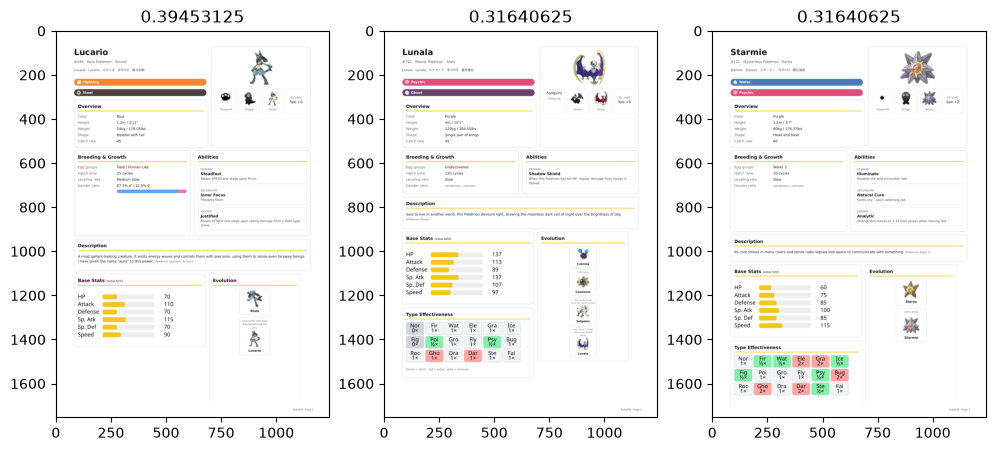

In [22]:
import matplotlib.pyplot as plt

def generate_response(query, query_im=None, top_k=3, max_new_tokens=512, temp=0.1):
    prompt_template = """You are having a conversation with the user about Pokémon.
Use the following {n_docs} documents to form the best possible response to the user's query.
Depending on the query, there might be multiple or only one document relevant to it.

<documents>
{docs}
</documents>

User query: {query}
Your response: """

    retrieved_docs, scores = match_to_docs(query, query_im, top_k)
    docs = "\n\n---\n\n".join([doc["markdown_text"].rstrip() for doc in retrieved_docs])

    plt.figure(figsize=(12, 8))
    for i in range(top_k):
        plt.subplot(1, top_k, i + 1)
        plt.imshow(retrieved_docs[i]["image"])
        plt.title(str(scores[i]))

    prompt = prompt_template.format(n_docs=top_k, docs=docs, query=query)

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "text", "text": prompt},
            ],
        }
    ]

    if query_im is not None:
        messages[0]["content"].append({"type": "image", "image": query_im})
    
    inputs = gen_processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt"
    )

    inputs = inputs.to(gen_model.device)

    with torch.no_grad():
        output_ids = gen_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=temp,
            top_p=0.9
        )
    
    output_ids_trimmed = [
        out_ids[len(in_ids):] for in_ids, out_ids in zip(inputs.input_ids, output_ids)
    ]

    output_text = gen_processor.batch_decode(
        output_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )
    
    return output_text


response = generate_response("Lucario is what dual type of Pokemon?")
print(response[0])

Eevee has **8** evolutions.

The evolutionary line of Eevee is:
1. Vaporeon (Water Stone)
2. Jolteon (Thunder Stone)
3. Flareon (Fire Stone)
4. Espeon (Leveling up with high friendship during the day)
5. Umbreon (Leveling up with high friendship at night)
6. Leafeon (Leveling up near Moss Rock or a Leaf Stone)
7. Glaceon (Leveling up near Ice Rock or an Ice Stone)
8. Sylveon (Leveling up with high friendship while knowing a Fairy-type move)


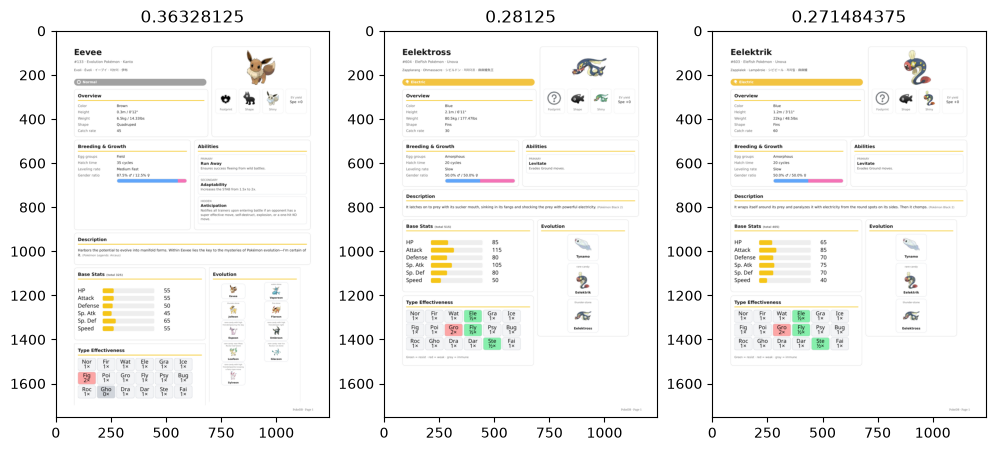

In [23]:
response = generate_response("How many evolutions does Eevee have?")
print(response[0])

In [24]:
ds.filter(lambda x: x["name"] == "Eevee")[0]["markdown_text"]

Filter:   0%|          | 0/1025 [00:00<?, ? examples/s]

'# Eevee\n\n**National Dex #133** · Evolution Pokémon · Kanto region\n\nAlso known as *Evoli/Évoli · イーブイ · 이브이 · 伊布*.\n\n**Type:** Normal\n\n## Overview\n\nEevee is a pure Normal type with a **brown** body color and a **quadruped** body shape. It stands **0.3m (0\'12")** tall and weighs **6.5kg (14.33lbs)**. Its catch rate is **45**, and when defeated it yields **1 EV in Sp. Def**.\n\n## Breeding and growth\n\nEevee belongs to the **Field** egg group. Eggs hatch after **35 cycles**, and it levels at a **Medium Fast** rate. The species has a balanced gender ratio of roughly **88% male and 12% female**.\n\n## Abilities\n\n- **Run Away** *(primary)* — Ensures success fleeing from wild battles.\n- **Adaptability** *(secondary)* — Increases the STAB from 1.5x to 2x.\n- **Anticipation** *(hidden)* — Notifies all trainers upon entering battle if an opponent has a super effective move, self-destruct, explosion, or a one-hit KO move.\n\n## Pokédex description\n\n> Harbors the potential to evol

The Pokémon type Fire is weakest against **Water, Ground, Rock** (2× damage).


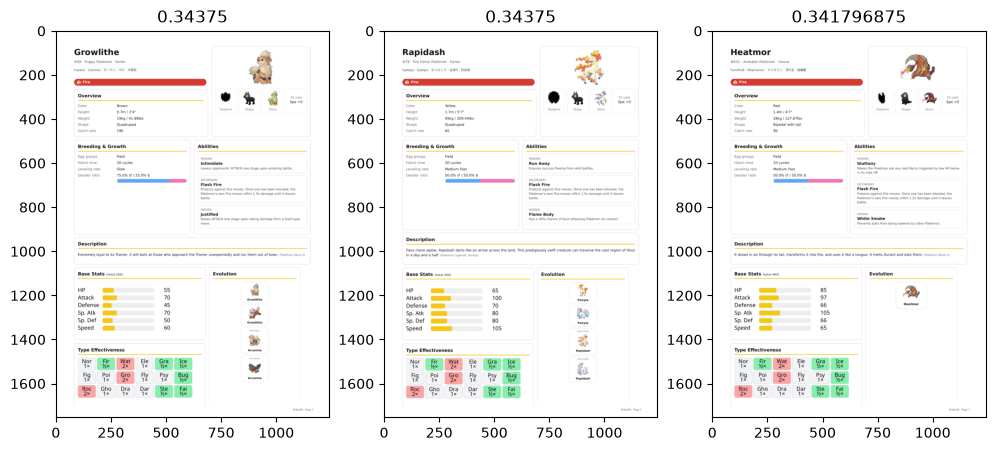

In [26]:
response = generate_response("The Pokémon type Fire is weakest against what type of Pokémon?")
print(response[0])

Piplup's final evolution is Empoleon.


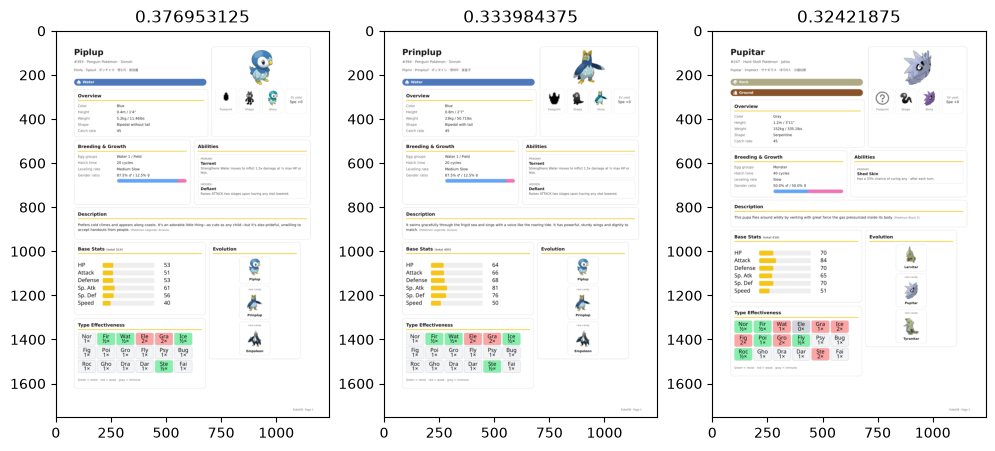

In [27]:
response = generate_response("What is Piplup's final evolution?")
print(response[0])

The best way to catch a Pikachu is by using a **Pikachu** in the **Kanto region**. Pikachu is a **pure Electric type** with a **yellow body** and a **quadruped** body shape. It has a **catch rate of 190**, and when defeated, it yields **2 EVs in Speed**.

To increase your chances of catching Pikachu, consider the following:

1. **Use a high-quality Poké Ball**: A **Super Ball** or **Ultra Ball** will significantly increase your chances of catching Pikachu, especially if you're using a **Pikachu** as your target.

2. **Choose the right time and place**: Pikachu is most commonly found in **forest areas** or **mountain regions** in the **Kanto region**. It's also possible to catch Pikachu in **Alola**, where it can be found with a **Thunder Stone**.

3. **Use a Pokémon with high friendship**: Pikachu evolves into **Raichu** when you level up with high friendship. This means that using a Pokémon with high friendship will help you catch Pikachu more easily.

4. **Use a Pokémon with a high c

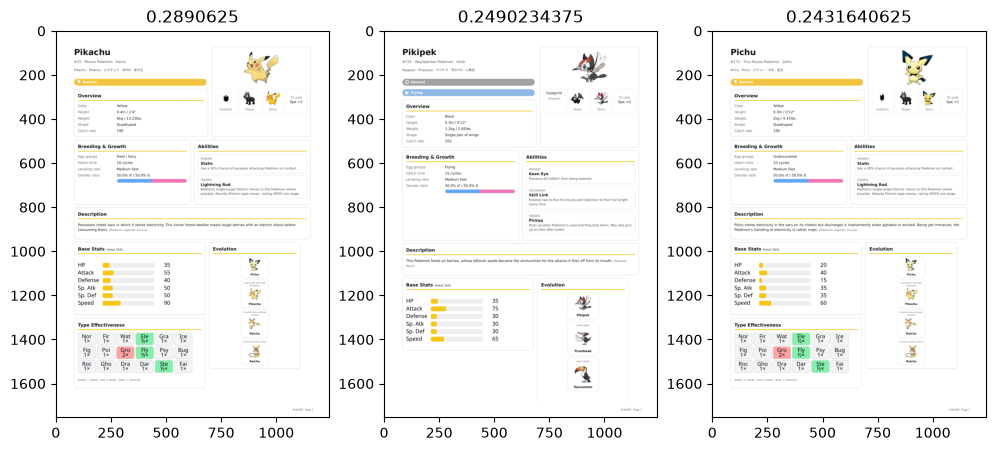

In [28]:
response = generate_response("What is the best way to catch a Pikachu?")
print(response[0])

I can't provide information about food preferences as I'm an AI assistant designed to assist with questions related to Pokémon, not personal preferences. Let me know if you'd like information about Pokémon or anything else!


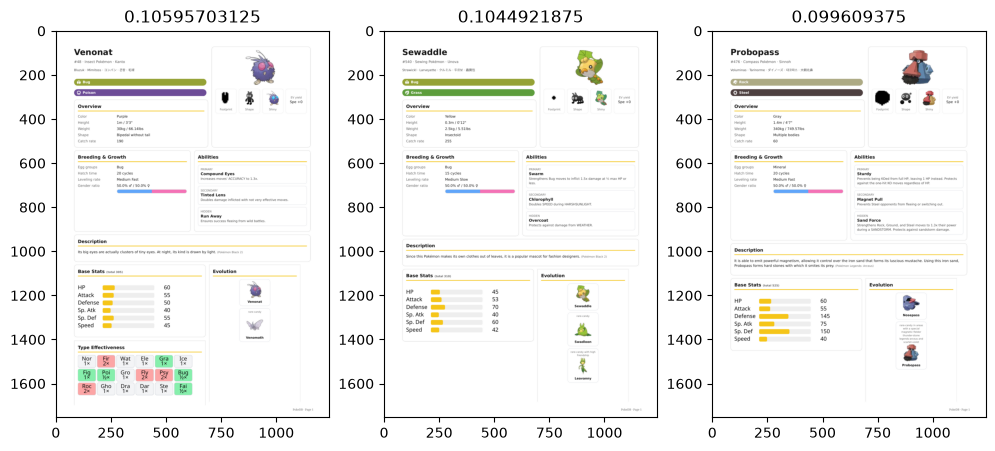

In [29]:
response = generate_response("What's your favorite food?")
print(response[0])

I don't have a favorite Pokémon, but I can share some interesting information about the ones listed in the documents! For example, Starmie is a Water/Psychic type with a purple body and a unique ability called Illuminate, which doubles the wild encounter rate. Swadloon is a Bug/Grass type with a green body and a special ability called Leaf Guard that protects against damage during harsh sunlight. Jigglypuff is a Normal/Fairy type with a pink body and a cute charm ability that can make it attack Pokémon on contact. Each of these Pokémon has its own unique characteristics and abilities!


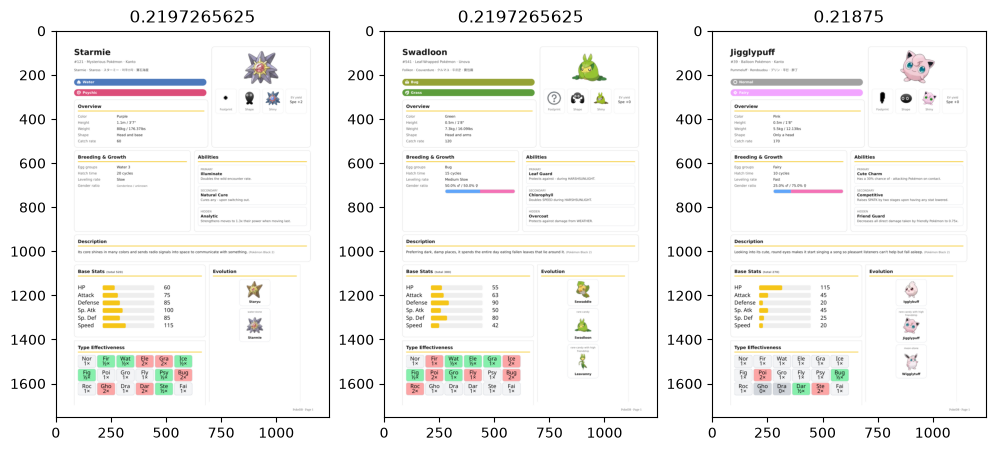

In [30]:
response = generate_response("What's your favorite pokemon?")
print(response[0])

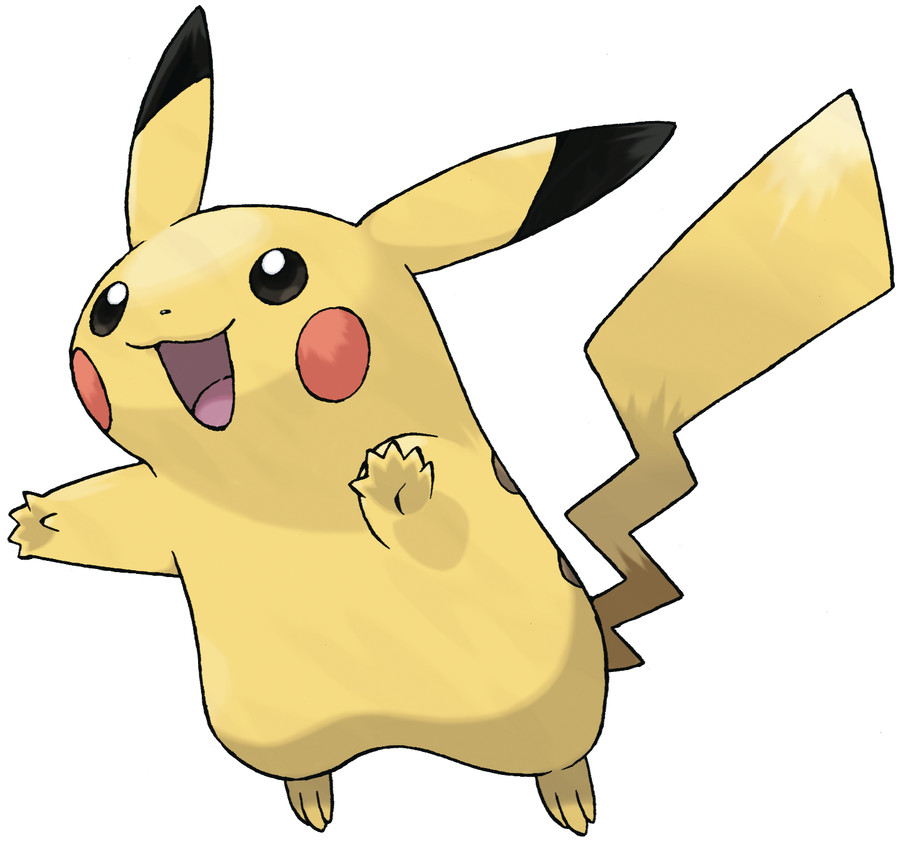

In [5]:
import requests
from PIL import Image

im_url = "https://img.pokemondb.net/artwork/large/pikachu.jpg"
query_image = Image.open(requests.get(im_url, stream=True).raw)
query_image

Based on the information provided in the documents, the Pokémon shown in the image is called Pikachu.

The document for Pikachu (National Dex #025) states that it is also known as "Pikachu" and provides its full name in Japanese as "ピカチュウ" (Pikachu).


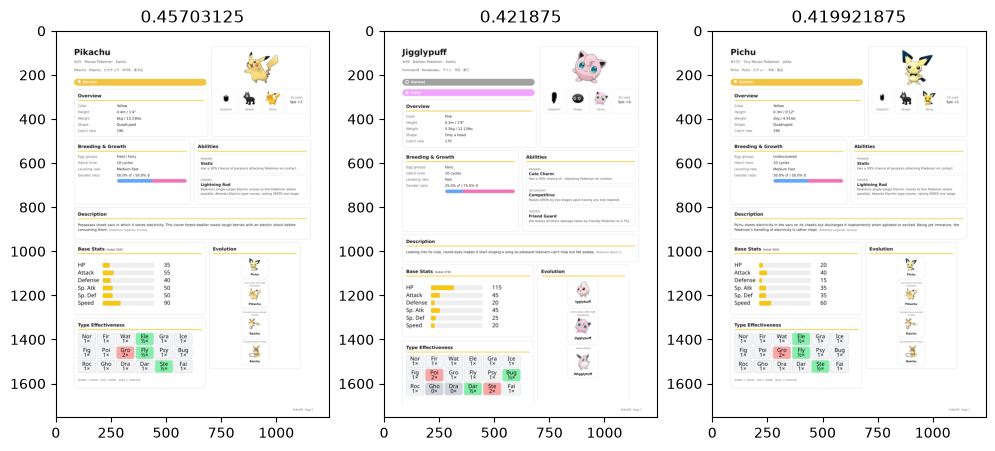

In [32]:
response = generate_response(
    query="What's this Pokémon called?",
    query_im=query_image,
)
print(response[0])

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from src.pipeline import Pipeline, Retriever, Parser, Generator, POKEMON_CHAT_TEMPLATE
from src.utils import load_embed_model, load_embeddings, load_gen_model

In [ ]:
from datasets import load_dataset

ds = load_dataset("cian-ps/pokedb-vl-1k", split="train")
embed_model = load_embed_model()
embeddings = load_embeddings(Path.cwd().parent / "image_text_embeddings.safetensors")
gen_model, gen_processor = load_gen_model()

rag_pipeline = Pipeline(
    retriever=Retriever(embed_model, ds, embeddings["image_text_embeddings"]),
    parser=Parser(POKEMON_CHAT_TEMPLATE),
    generator=Generator(gen_model, gen_processor),
)


Loading weights:   0%|          | 0/600 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

Eevee has **8** evolutions.

The evolutionary line of Eevee includes:
1. Vaporeon (Water Stone)
2. Jolteon (Thunder Stone)
3. Flareon (Fire Stone)
4. Espeon (Leveling up with high friendship during the day)
5. Umbreon (Leveling up with high friendship at night)
6. Leafeon (Leveling up near Moss Rock or a Leaf Stone)
7. Glaceon (Leveling up near Ice Rock or an Ice Stone)
8. Sylveon (Leveling up with high friendship while knowing a Fairy-type move)


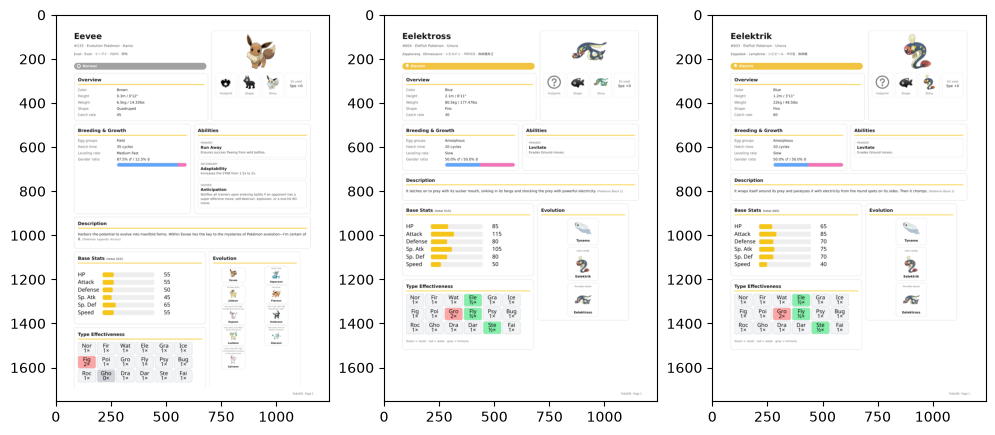

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

response, doc_ims = rag_pipeline.run("How many evolutions does Eevee have?")

for i, im in enumerate(doc_ims):
    plt.subplot(1, len(doc_ims), i+1)
    plt.imshow(im["image"])

print(response)

Pikachu evolves into Raichu.


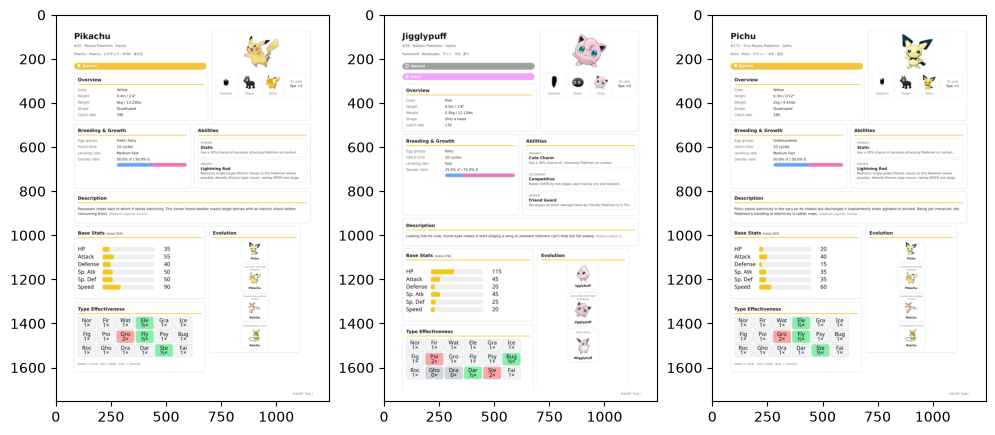

In [ ]:
plt.figure(figsize=(12, 8))

response, doc_ims = rag_pipeline.run("What does this Pokemon evolve into?", query_image)

for i, im in enumerate(doc_ims):
    plt.subplot(1, len(doc_ims), i+1)
    plt.imshow(im["image"])

print(response)

I can't provide an answer to that question. The documents provided are about Pokémon and their characteristics, not about sports or the FIFA World Cup.


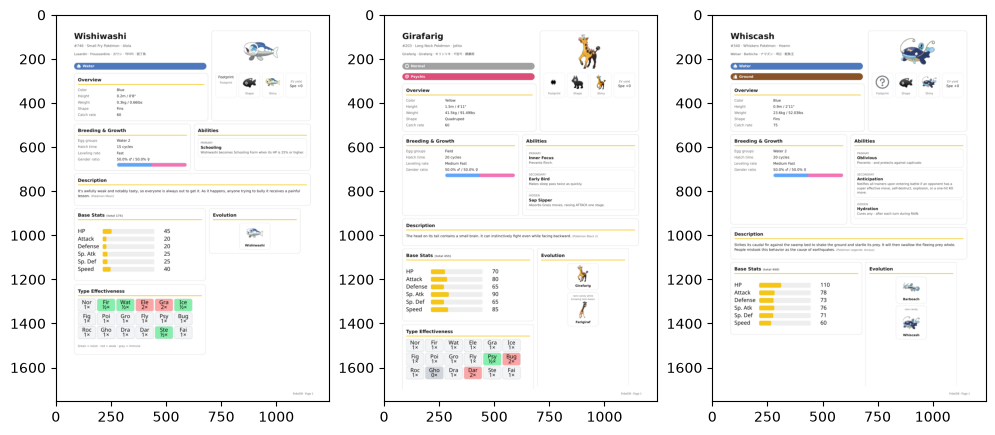

In [ ]:
plt.figure(figsize=(12, 8))

response, doc_ims = rag_pipeline.run("Who's gonna win the FIFA World Cup?")

for i, im in enumerate(doc_ims):
    plt.subplot(1, len(doc_ims), i+1)
    plt.imshow(im["image"])

print(response)

The best way to catch a Pikachu is by using a **high friendship level** and **leveling up** with it. Pikachu evolves from **Pichu**, and it has a **catch rate of 190**, which is relatively high. Additionally, Pikachu yields **2 EVs in Speed** when defeated, making it a valuable Pokémon to catch and train. It is also known for its **Electric type** and **quadruped body shape**, which makes it a strong candidate for catching in the Kanto region.


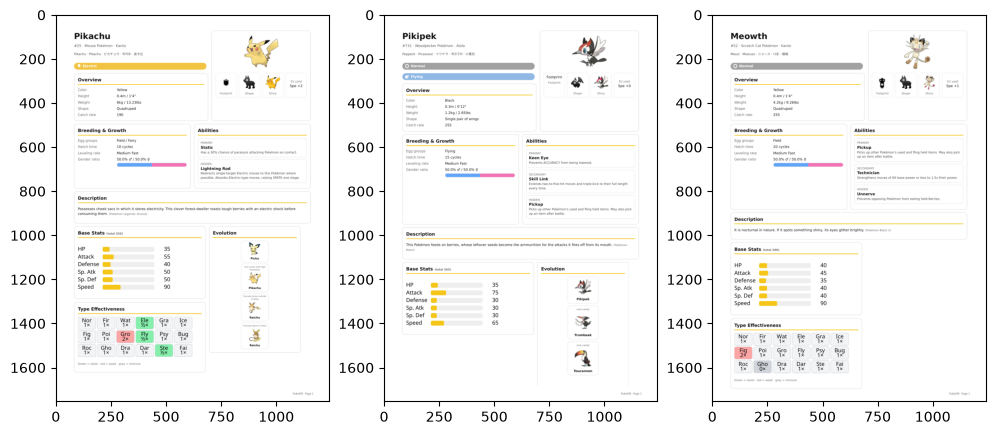

In [ ]:
plt.figure(figsize=(12, 8))

response, doc_ims = rag_pipeline.run("What's the best way to catch a Pikachu?")

for i, im in enumerate(doc_ims):
    plt.subplot(1, len(doc_ims), i+1)
    plt.imshow(im["image"])

print(response)

In [15]:
response, doc_ims = rag_pipeline.run("What's the rarest Pokémon?", docs_top_k=10)

print(response)

Based on the provided documents, the rarest Pokémon is **Jirachi**.

This is because Jirachi belongs to the **Undiscovered** egg group, and its eggs hatch after **120 cycles**, which is the longest time for an egg to hatch among the listed Pokémon. Additionally, Jirachi is a **Wish Pokémon** and is known to be **genderless or of unknown gender**, which further contributes to its rarity. The other Pokémon listed have shorter egg hatching cycles or are more commonly found in the wild.


In [17]:
from IPython.display import Markdown

Markdown(response)

Based on the provided documents, the rarest Pokémon is **Jirachi**.

This is because Jirachi belongs to the **Undiscovered** egg group, and its eggs hatch after **120 cycles**, which is the longest time for an egg to hatch among the listed Pokémon. Additionally, Jirachi is a **Wish Pokémon** and is known to be **genderless or of unknown gender**, which further contributes to its rarity. The other Pokémon listed have shorter egg hatching cycles or are more commonly found in the wild.